In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Localizar o CSV atualizado
caminho = Path("../regressao/dados/partidas_simuladas.csv")

if not caminho.exists():
    caminho = Path("regressao/dados/partidas_simuladas.csv")

# Carregar os dados
df = pd.read_csv(caminho)

sns.set_theme(style="whitegrid")

# Variáveis utilizadas na regressão atual
features = [
    "distancia_percorrida_unidades",
    "dano_recebido",
    "itens_coletados",
    "salas_exploradas",
    "tempo_decorrido_min"
]

alvo = "tempo_restante_min"

print("DADOS CARREGADOS COM SUCESSO!")
print("Quantidade de registros:", len(df))
print("Quantidade de colunas:", len(df.columns))
print("\nVariáveis explicativas:")
print(features)
print("\nVariável-alvo:", alvo)

display(df.head())


DADOS CARREGADOS COM SUCESSO!
Quantidade de registros: 600
Quantidade de colunas: 8

Variáveis explicativas:
['distancia_percorrida_unidades', 'dano_recebido', 'itens_coletados', 'salas_exploradas', 'tempo_decorrido_min']

Variável-alvo: tempo_restante_min


,id_snapshot,distancia_percorrida_unidades,dano_recebido,itens_coletados,salas_exploradas,tempo_decorrido_min,tempo_restante_min,origem_dados
0,1,432.85,0,10,8,7.33,22.17,simulados
1,2,782.58,0,1,3,3.00,26.39,simulados
2,3,1300.19,3,3,7,13.91,16.61,simulados
3,4,1464.60,0,12,2,14.55,20.17,simulados
4,5,1724.70,2,1,1,4.58,24.40,simulados


In [6]:
# Informações gerais
df.info()

print("\nValores ausentes:")
display(df.isnull().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nEstatísticas descritivas:")
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_snapshot                    600 non-null    int64  
 1   distancia_percorrida_unidades  600 non-null    float64
 2   dano_recebido                  600 non-null    int64  
 3   itens_coletados                600 non-null    int64  
 4   salas_exploradas               600 non-null    int64  
 5   tempo_decorrido_min            600 non-null    float64
 6   tempo_restante_min             600 non-null    float64
 7   origem_dados                   600 non-null    str    
dtypes: float64(3), int64(4), str(1)
memory usage: 37.6 KB

Valores ausentes:


id_snapshot                      0
distancia_percorrida_unidades    0
dano_recebido                    0
itens_coletados                  0
salas_exploradas                 0
tempo_decorrido_min              0
tempo_restante_min               0
origem_dados                     0
dtype: int64


Registros duplicados:
0

Estatísticas descritivas:


,id_snapshot,distancia_percorrida_unidades,dano_recebido,itens_coletados,salas_exploradas,tempo_decorrido_min,tempo_restante_min
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,922.996050,1.551667,6.110000,5.126667,12.396050,17.916417
std,173.349358,513.824846,1.135553,3.731547,3.151800,6.545347,7.270039
min,1.000000,41.200000,0.000000,0.000000,0.000000,1.020000,1.010000
25%,150.750000,473.167500,1.000000,3.000000,2.000000,6.760000,11.987500
50%,300.500000,900.730000,2.000000,6.000000,5.000000,11.985000,18.330000
75%,450.250000,1372.230000,3.000000,9.000000,8.000000,18.312500,23.552500
max,600.000000,1798.900000,3.000000,12.000000,10.000000,23.930000,36.190000


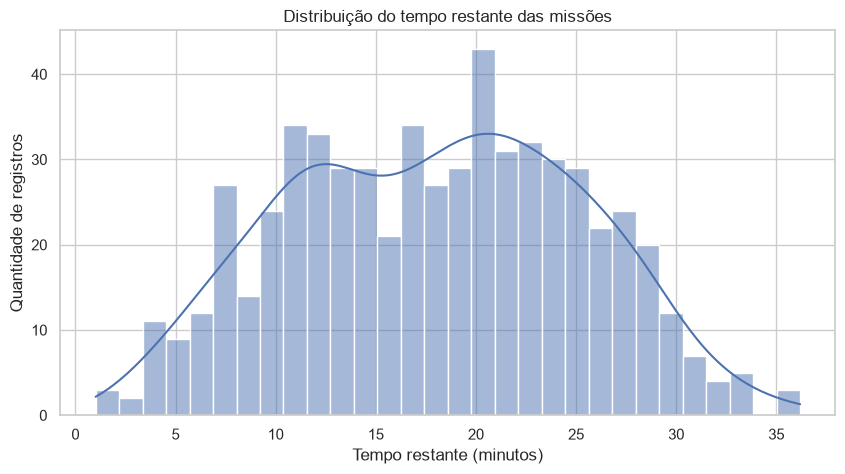

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tempo_restante_min",
    bins=30,
    kde=True
)

plt.title("Distribuição do tempo restante das missões")
plt.xlabel("Tempo restante (minutos)")
plt.ylabel("Quantidade de registros")

plt.show()

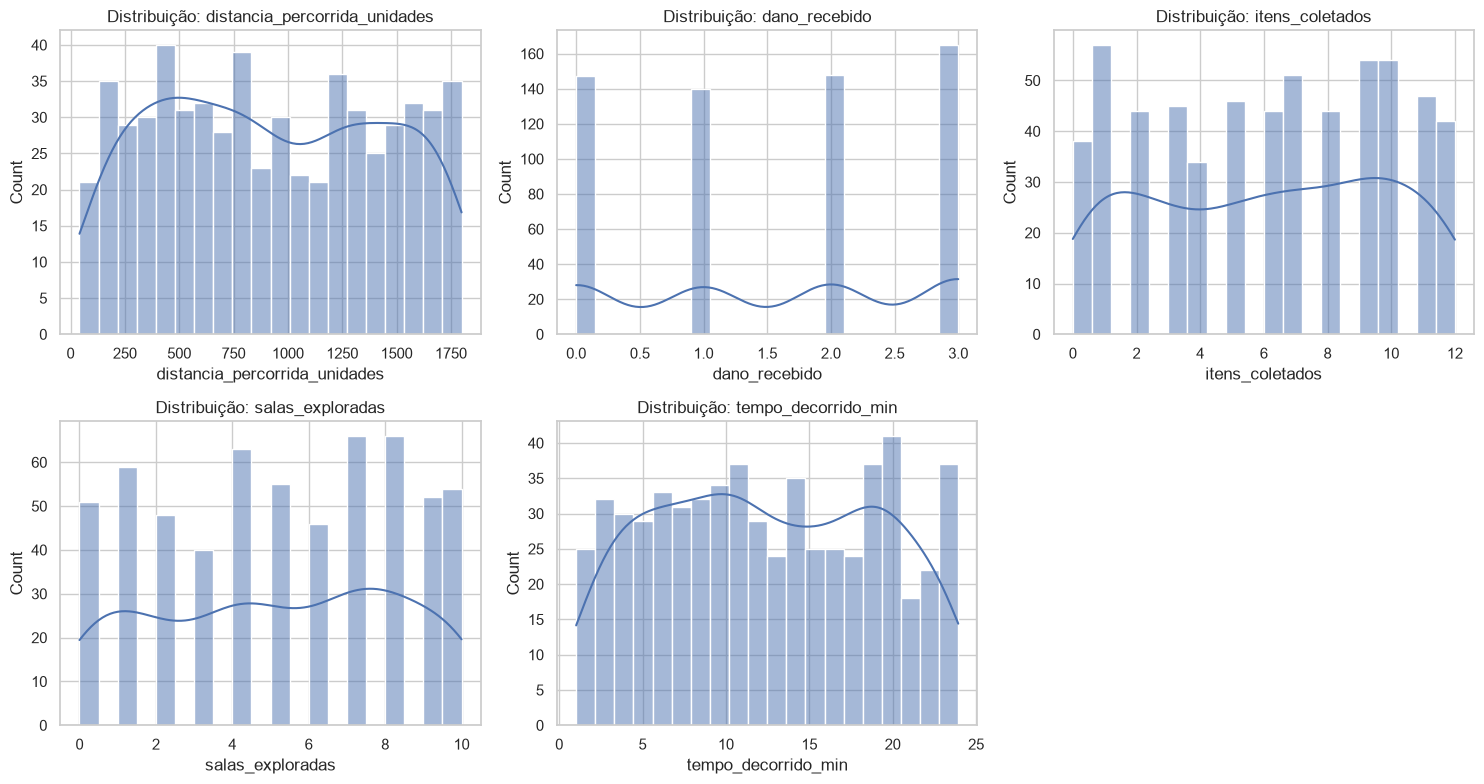

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, coluna in enumerate(features):
    sns.histplot(data=df, x=coluna, bins=20, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribuição: {coluna}")
    axes[i].set_xlabel(coluna)

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

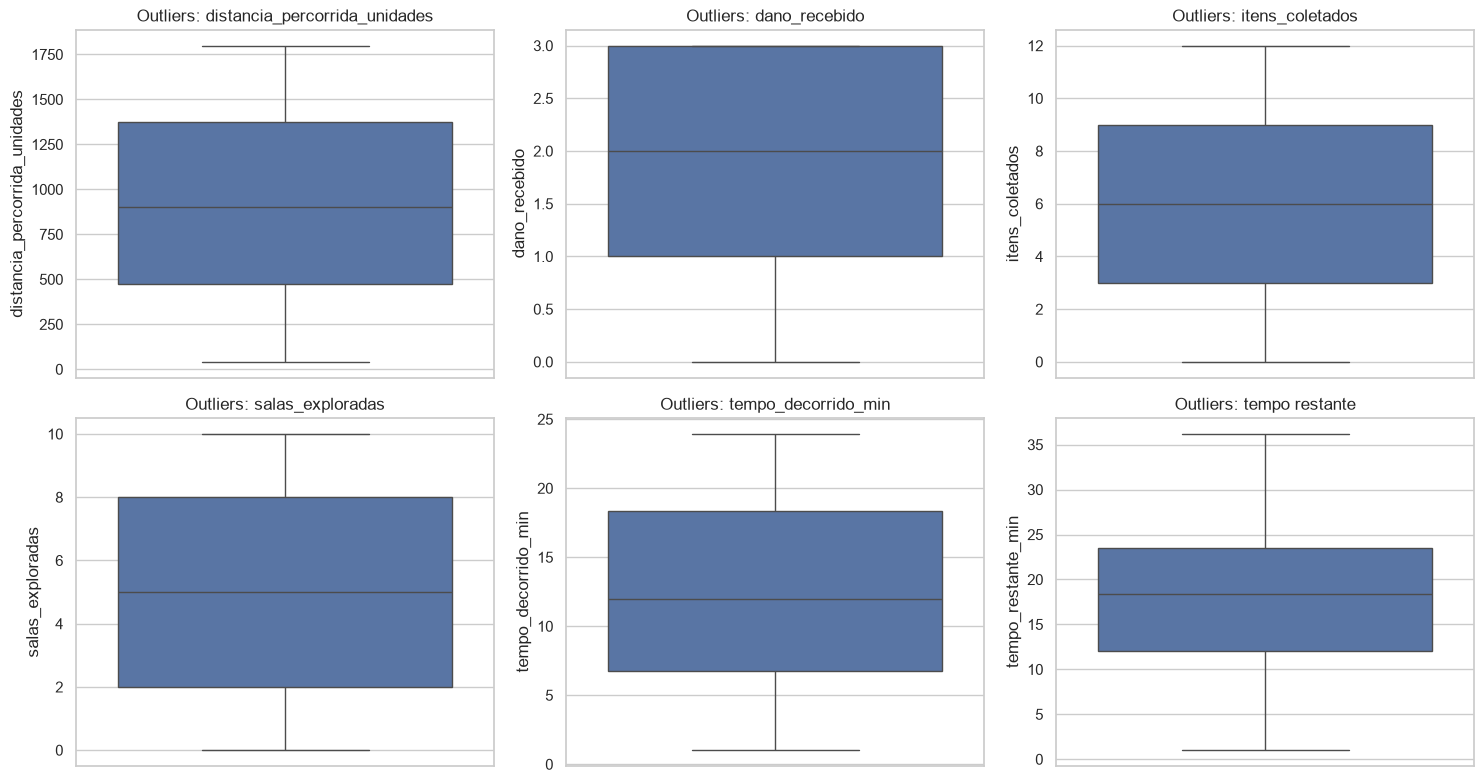

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, coluna in enumerate(features):
    sns.boxplot(data=df, y=coluna, ax=axes[i])
    axes[i].set_title(f"Outliers: {coluna}")

sns.boxplot(data=df, y=alvo, ax=axes[5])
axes[5].set_title("Outliers: tempo restante")

plt.tight_layout()
plt.show()

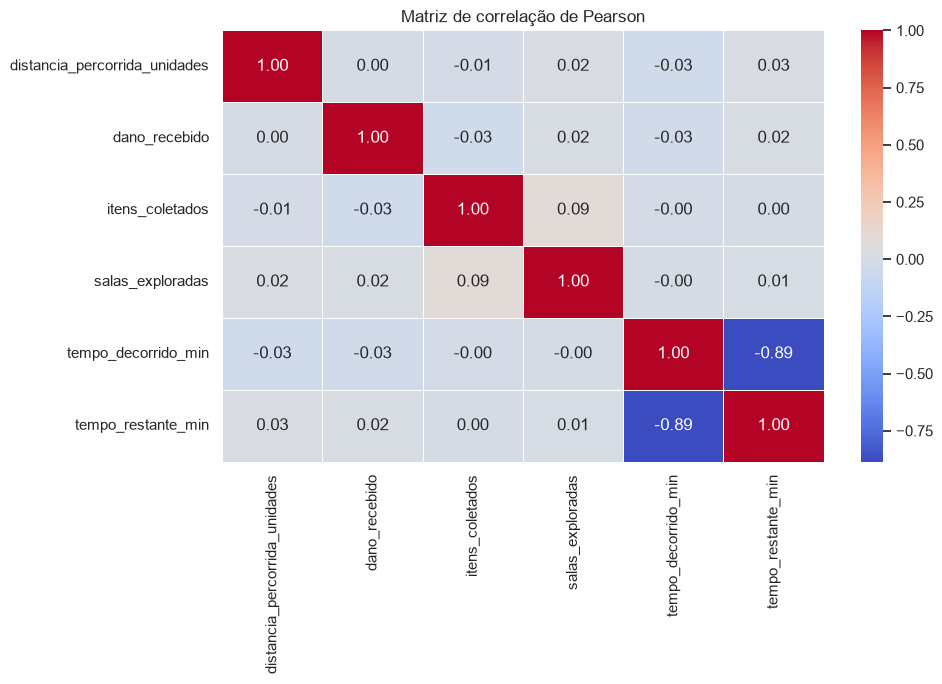

In [9]:
plt.figure(figsize=(10, 7))

correlacao = df[features + [alvo]].corr(method="pearson")

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlação de Pearson")
plt.tight_layout()
plt.show()

In [10]:
df_limpo = df.copy()

for coluna in features + [alvo]:
    Q1 = df_limpo[coluna].quantile(0.25)
    Q3 = df_limpo[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    df_limpo = df_limpo[
        (df_limpo[coluna] >= limite_inferior) &
        (df_limpo[coluna] <= limite_superior)
    ]

print("Registros antes da remoção:", len(df))
print("Registros após a remoção:", len(df_limpo))
print("Outliers removidos:", len(df) - len(df_limpo))

Registros antes da remoção: 600
Registros após a remoção: 600
Outliers removidos: 0


In [11]:
X = df_limpo[features]
y = df_limpo[alvo]

print("Dados preparados com sucesso!")
print("Formato das variáveis explicativas:", X.shape)
print("Formato da variável-alvo:", y.shape)

Dados preparados com sucesso!
Formato das variáveis explicativas: (600, 5)
Formato da variável-alvo: (600,)


In [12]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Divisão realizada com sucesso!")
print("Dados de treino:", X_treino.shape)
print("Dados de teste:", X_teste.shape)

Divisão realizada com sucesso!
Dados de treino: (480, 5)
Dados de teste: (120, 5)


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

modelos = {
    "Regressão Linear": Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", LinearRegression())
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    )
}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    print(f"{nome} treinado com sucesso!")

Regressão Linear treinado com sucesso!
Random Forest treinado com sucesso!


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

resultados = []

for nome, modelo in modelos.items():
    previsoes = modelo.predict(X_teste)

    mae = mean_absolute_error(y_teste, previsoes)
    mse = mean_squared_error(y_teste, previsoes)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_teste, previsoes)

    resultados.append({
        "Modelo": nome,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

comparacao = pd.DataFrame(resultados)

display(comparacao.round(4))

,Modelo,MAE,MSE,RMSE,R²
0,Regressão Linear,2.7758,11.3308,3.3661,0.7838
1,Random Forest,2.9609,13.2131,3.6350,0.7479


In [15]:
melhor_indice = comparacao["RMSE"].idxmin()
melhor_modelo_nome = comparacao.loc[melhor_indice, "Modelo"]

print("COMPARAÇÃO FINAL DOS MODELOS")
display(comparacao.round(4))

print("\nMelhor modelo:", melhor_modelo_nome)
print("Critério: menor RMSE")

print("\nQuantidade de registros utilizados:", len(df_limpo))
print("Quantidade de variáveis explicativas:", len(features))
print("Variável prevista:", alvo)

COMPARAÇÃO FINAL DOS MODELOS


,Modelo,MAE,MSE,RMSE,R²
0,Regressão Linear,2.7758,11.3308,3.3661,0.7838
1,Random Forest,2.9609,13.2131,3.6350,0.7479



Melhor modelo: Regressão Linear
Critério: menor RMSE

Quantidade de registros utilizados: 600
Quantidade de variáveis explicativas: 5
Variável prevista: tempo_restante_min
